# Business grouping and peer evaluation

This report compares four saved v0 peer-selection routes with three reviewers, audits company business groups against dated primary sources, and tests whether grouping context improves peer selection and EV/EBITDA estimates. One company keeps one Capital IQ identifier.

Product-market evidence can refine broad industry codes ([Hoberg and Phillips, 2017](https://pubsonline.informs.org/doi/abs/10.1287/mnsc.2016.2693)); a product list alone does not establish an accounting segment ([IFRS 8 discussion](https://www.ifrs.org/content/dam/ifrs/meetings/2017/march/cmac/ap4-ifrs8.pdf)). Here a business group is an economic activity cluster for matching, not a reported segment.


## 1. Inputs and evaluation definitions

The team reviewed 36 PCTY/WEN peer pairs: Riya, Barbara, and Matthew each scored 0 (not comparable), 1 (adjacent), or 2 (direct). Four saved routes are scored separately against each reviewer using the same frozen pool and `golden_set.py`: precision@10, direct hits@10, and NDCG@10. There is no invented majority label.

The source audit checks ten selected profiles against dated company sources: 34 activity statuses (current/exited) and nine exact current-business partitions. These cases exposed possible errors, so this is a targeted regression check, not a blinded estimate of population accuracy. The downstream tests compare the unchanged peer judge with a judge given current-business context, on ten development targets and six targets in the existing fixed holdout.


In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data_manifest.json").exists())
BASE = ROOT / "outputs-local/comps_pilot_targets"
REVIEW = BASE / "golden_set/reviewer_evaluation"
SPLIT = BASE / "business_structure_refinement"
SOURCE = SPLIT / "source_benchmark"
DEV = SPLIT / "peer_test"
HOLDOUT = SPLIT / "holdout_test"
for path in (REVIEW / "route_metrics.csv", SPLIT / "split_classification/company_comparison.csv",
             SOURCE / "summary.json", DEV / "valuation_comparison.csv",
             HOLDOUT / "valuation_comparison.csv"):
    assert path.exists(), f"Missing output: {path}"
print("Saved local outputs loaded.")

Saved local outputs loaded.


## 2. Four routes against each reviewer

In [2]:
metrics = pd.read_csv(REVIEW / "route_metrics.csv")
pairs = pd.read_csv(REVIEW / "pair_agreement.csv")
agreement = pd.read_csv(REVIEW / "reviewer_agreement.csv")
mean = metrics.loc[metrics.target.eq("mean"),
                   ["reviewer", "route", "listed in top 10", "precision@10", "direct hits@10", "NDCG@10"]]
display(mean.round(3))
display(agreement.round(3))
print(f"Unanimous pairs: {int(pairs.unanimous.sum())}/{len(pairs)}; disputed: {int((~pairs.unanimous).sum())}")

,reviewer,route,listed in top 10,precision@10,direct hits@10,NDCG@10
8,riya,cosine similarity,10.0,0.95,5.0,0.871
9,riya,cosine then LLM good comps,4.0,1.00,3.5,0.591
10,riya,LLM picks directly,4.0,1.00,3.5,0.569
11,riya,LLM picks then cosine,4.0,1.00,3.5,0.569
20,barbara,cosine similarity,10.0,0.50,1.5,0.844
21,barbara,cosine then LLM good comps,4.0,1.00,1.5,0.852
22,barbara,LLM picks directly,4.0,1.00,1.5,0.796
23,barbara,LLM picks then cosine,4.0,1.00,1.5,0.796
32,matthew,cosine similarity,10.0,0.45,2.5,0.910
33,matthew,cosine then LLM good comps,4.0,1.00,2.5,0.907


,reviewer_a,reviewer_b,exact_agreement,pairs,agreement_rate
0,riya,barbara,12,36,0.333
1,riya,matthew,12,36,0.333
2,barbara,matthew,30,36,0.833


Unanimous pairs: 11/36; disputed: 25


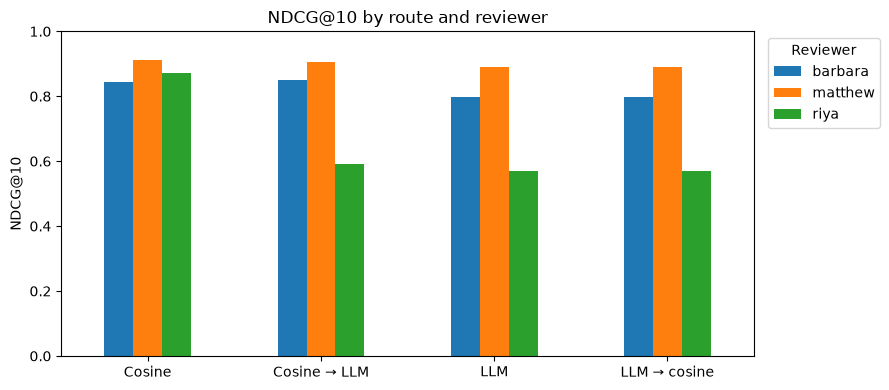

In [3]:
plot = mean.pivot(index="route", columns="reviewer", values="NDCG@10")
plot = plot.reindex(["cosine similarity", "cosine then LLM good comps",
                     "LLM picks directly", "LLM picks then cosine"])
plot.index = ["Cosine", "Cosine → LLM", "LLM", "LLM → cosine"]
ax = plot.plot.bar(figsize=(9, 4), ylim=(0, 1), rot=0, title="NDCG@10 by route and reviewer")
ax.set_ylabel("NDCG@10")
ax.legend(title="Reviewer", loc="upper left", bbox_to_anchor=(1.01, 1))
ax.figure.tight_layout()
plt.show()

The reviewers agree on 11 of 36 pairs. Cosine returns ten peers per target; the LLM routes return four. Precision@10 uses the number returned, while NDCG@10 assesses rank and coverage against the ideal pooled ordering. PCTY and WEN have one business each, so their labels do not validate multi-business grouping.


## 3. Business grouping and primary-source audit

A complete source-cited partition takes priority over conflicting pairwise model labels. Otherwise, current activities join when related or unresolved, unless a direct distinct-business judgment separates them. Dated completed sales remove activities from current scope while preserving their history. Every current activity belongs to one group under its original company ID.

The correction record cites [UFPT's completed Molded Fiber sale](https://ufpt.com/ufp-technologies-sells-molded-fiber-business-to-ckf-inc/), [Brown & Brown's Retail and Specialty Distribution segments](https://investor.bbrown.com/static-files/7f3bbce4-ed64-430a-87b7-2e69375f0f4a), and [Silgan's proposed transaction](https://www.silganholdings.com/news/news-details/2026/Silgan-Announces-Strategic-Portfolio-Acceleration-Establishes-Partnership-to-Acquire-Trivium/default.aspx), which had not closed. See `primary_source_reference.json` and `source_corrections.json` for activity-level evidence.


In [4]:
split = pd.read_csv(SPLIT / "split_classification/company_comparison.csv")
source = json.loads((SOURCE / "summary.json").read_text(encoding="utf-8"))
display(pd.DataFrame([
    {"check": "current/exited activity", "cases": source["activity_labels"],
     "saved correct": source["activity_correct_saved"], "refined correct": source["activity_correct_refined"]},
    {"check": "exact current group partition", "cases": source["group_reference_cases"],
     "saved correct": source["group_exact_saved"], "refined correct": source["group_exact_refined"]},
]))
print(f"Profiles: {len(split)}; multi-business: "
      f"{split.refined_decision.eq('multiple_businesses').sum()}; "
      f"pair-label conflicts: {split.pair_conflicts.gt(0).sum()}")
display(split.loc[split.ticker.isin(["UFPT", "BRO", "SLGN", "BBCP"]),
                  ["ticker", "old_groups", "refined_groups", "exited", "source_corrections", "pair_conflicts"]])
display(pd.read_csv(SOURCE / "activity_status.csv").query("saved_correct == False")
        [["ticker", "business_id", "reference", "saved", "refined"]])

,check,cases,saved correct,refined correct
0,current/exited activity,34,27,34
1,exact current group partition,9,7,9


Profiles: 40; multi-business: 8; pair-label conflicts: 4


,ticker,old_groups,refined_groups,exited,source_corrections,pair_conflicts
4,BRO,1,2,0,4,4
7,SLGN,1,1,0,3,0
22,UFPT,1,1,1,1,0
38,BBCP,2,2,0,0,1


,ticker,business_id,reference,saved,refined
26,BRO,B2,current,unresolved,current
27,BRO,B3,current,unresolved,current
28,BRO,B4,current,unresolved,current
29,SLGN,B1,current,unresolved,current
30,SLGN,B2,current,unresolved,current
31,SLGN,B3,current,unresolved,current
33,UFPT,B2,exited,unresolved,exited


## 4. Paired development test

Ten selected development targets yield 137 candidate pairs from the updated SIC2 run. Both conditions use `gpt-6.1-sol`, the same similarity-weighted EV/EBITDA estimator, and the same no-matching fallback. Only the peer judge's business-scope context changes. Prompts, responses, decisions, and estimates are saved in `peer_test/`.


,mode,matched targets,median APE (%),changed peer decisions
0,control,7,19.26,0
1,selective_scope,7,39.41,4


mode,control,selective_scope
ticker,,
AFG,11.4,3.2
AZZ,66.8,66.8
BBCP,53.0,53.0
BOC,12.3,45.0
BUKS,26.2,26.2
CSL,3.8,55.0
NWSA,44.5,44.5
PCTY,34.3,34.3
SNFC.A,7.0,7.0


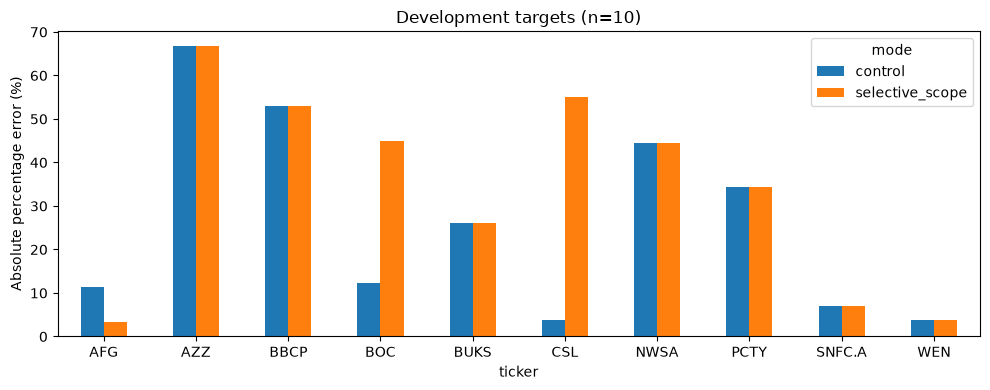

In [5]:
def comparison(folder):
    summary = json.loads((folder / "summary.json").read_text(encoding="utf-8"))
    values = pd.read_csv(folder / "valuation_comparison.csv")
    paired = values.pivot(index="ticker", columns="mode", values="absolute_percentage_error")
    table = pd.DataFrame([
        {"mode": mode, "matched targets": summary[mode]["matched_targets"],
         "median APE (%)": summary[mode]["median_ape"],
         "changed peer decisions": summary["changed_peer_decisions"] if mode == "selective_scope" else 0}
        for mode in ("control", "selective_scope")
    ])
    return summary, paired, table

dev_summary, dev_paired, dev_table = comparison(DEV)
display(dev_table.round(2))
display(dev_paired.round(1))
ax = dev_paired[["control", "selective_scope"]].plot.bar(figsize=(10, 4), rot=0)
ax.set_ylabel("Absolute percentage error (%)")
ax.set_title("Development targets (n=10)")
ax.figure.tight_layout()
plt.show()

## 5. Fixed-holdout test

Six source-pilot firms are in the original holdout: ADUS, TECH, BV, LMB, LUCK, and RYAN. They were not moved into training. The saved training-company embedding cache generated 74 candidate rows; the v0 judge threshold retained 72. Comparison with 550 saved facet-cosine values found a maximum absolute difference below 5 × 10⁻⁷. No holdout outcome was used to design the tested split rule. The six firms form a source-pilot subset, not a random sample.


,mode,matched targets,median APE (%),changed peer decisions
0,control,4,31.02,0
1,selective_scope,5,40.21,1


mode,control,selective_scope
ticker,,
ADUS,13.7,13.7
BV,59.0,59.0
LMB,22.4,22.4
LUCK,9.6,40.7
RYAN,51.2,51.2
TECH,39.7,39.7


,mode,score,reason


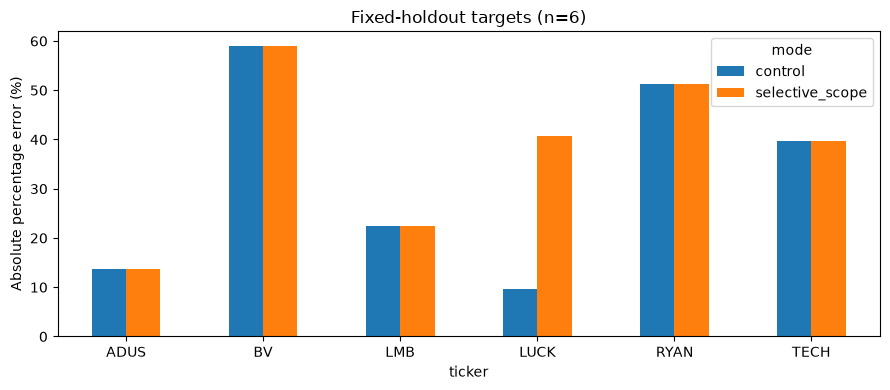

In [6]:
hold_summary, hold_paired, hold_table = comparison(HOLDOUT)
display(hold_table.round(2))
display(hold_paired.round(1))
peers = pd.read_csv(HOLDOUT / "peer_judgments.csv")
display(peers.loc[peers.ticker.eq("LUCK") & peers.comp.eq("PRKS"),
                  ["mode", "score", "reason"]])
ax = hold_paired[["control", "selective_scope"]].plot.bar(figsize=(9, 4), rot=0)
ax.set_ylabel("Absolute percentage error (%)")
ax.set_title("Fixed-holdout targets (n=6)")
ax.figure.tight_layout()
plt.show()

## 6. Interpretation and adoption decision

In the targeted source check, correct activity statuses rise from 27/34 to 34/34 and exact group partitions from 7/9 to 9/9. Eight of the 40 profiles have multiple current business groups. These are corrections on the checked cases, not an accuracy estimate over all firms.

Business-scope context changes 4/137 development peer decisions; coverage remains 7/10 and median APE rises from 19.26% to 39.41%. On the six holdout targets, it changes 1/72 decisions, raises matched-peer coverage from 4/6 to 5/6, and raises median APE from 31.02% to 40.21%. The changed holdout pair is LUCK–PRKS. [Lucky Strike's FY2026 filing](https://www.sec.gov/Archives/edgar/data/1840572/000162828026059179/bowl-20260628.htm) reports five water parks among 366 locations; [United Parks](https://unitedparks.com/our-brands/water-parks/) also operates water parks. That shared line is insufficient for whole-company valuation comparison. LUCK's APE rises from 9.58% to 40.74% when PRKS is accepted.

**Decision:** retain the corrected, source-linked grouping as company metadata. Do not use this scope prompt as the default peer rule: median valuation error worsens in both tested sets. The separate `changed_pair_source_audit.json` contains post-run analyst diagnostics, not blinded peer labels.
